# 09 三例刚性配准试验与公开终点决策

按影像条件选择10005_L1（常规厚层FLAIR）、10029_L2（3D FLAIR）及40158_L1（已知坐标视野边界）。不按RN结局选例。T1为fixed、FLAIR为moving；变换由fixed物理LPS点映射到moving物理LPS点。原影像、分割及临床标签不覆盖。试验会产生经过线性插值的派生显示图；插值不能恢复采集层间隙或视野外信息。

In [1]:
from pathlib import Path
import sys,json,runpy,hashlib
import pandas as pd
import SimpleITK as sitk
ROOT=Path.cwd()
if ROOT.name=='notebooks':ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
print('SimpleITK',sitk.Version_VersionString())
receipt=json.loads((ROOT/'data/metadata/endpoint_gate_20261029/clinical_source_recheck.json').read_text())
p=ROOT/'data/raw/openbtai_molab_current/OpenBTAI_METS_ClinicalData_Nov2023.xlsx'
assert hashlib.sha256(p.read_bytes()).hexdigest()==receipt['prior_sha256']
print('Clinical source unchanged on 2026-10-29:',receipt['unchanged'])

SimpleITK 2.5.6
Clinical source unchanged on 2026-10-29: True


## 方法试验

首轮GradientDescent的3例全量互信息均变差，作为失败试验保存在单独CSV、JSON及图中。当前仅重试一次RegularStepGradientDescent，步长0.5、最小步长0.005，三层金字塔[4,2,1]，随机采样20%、固定种子、单线程。配准临时网格2mm；在同一3mm网格评估全量负互信息和强度前景视野重叠。强度前景不是脑分割。数值工程筛查要求负互信息下降且前景视野重叠减少≤2个百分点；通过也不代表临床解剖对齐。

In [2]:
pilot=runpy.run_path(str(ROOT/'scripts/run_registration_pilot.py'))['run'](repeat_first=True)
f=pd.read_csv(ROOT/'data/processed/registration_pilot.csv')
print(f[['lesion_key','negative_mi_before','negative_mi_after','translation_norm_mm','foreground_fov_overlap_before','foreground_fov_overlap_after','target_coordinate_fov_before','target_coordinate_fov_after','candidate_status']].to_string(index=False))
assert pilot['verified_source_files']==793
assert f.applied_to_analysis.sum()==f.clinical_alignment_accepted.sum()==f.use_for_model.sum()==0
print('First-case repeated parameter difference:',pilot['cases'][0]['metrics']['repeat_max_parameter_difference'])

Rigid pilot 10005_L1 conventional_thick_slice_flair
Rigid pilot 10029_L2 three_dimensional_flair
Rigid pilot 40158_L1 known_coordinate_fov_boundary
lesion_key               selection_reason  negative_mi_before  negative_mi_after  metric_improved  translation_norm_mm  max_abs_rotation_degrees  foreground_fov_overlap_before  foreground_fov_overlap_after  target_coordinate_fov_before  target_coordinate_fov_after                                                                                                                          optimizer_stop  clinical_alignment_accepted  use_for_model  metric_screen_pass                           candidate_status  applied_to_analysis
  10005_L1 conventional_thick_slice_flair           -0.433252          -0.077393                0           128.682891                 10.547648                       0.955862                      0.237273                         1.000                          0.0                                                     Regula

## 失败试验及候选图

收敛标志和目标坐标视野比例均不能代替配准质量。以下显示10005_L1的候选变换审阅图；该例变换已拒绝。另见[10029_L2](../outputs/registration-pilot-20261029/10029_L2_registration_review.png)、[40158_L1](../outputs/registration-pilot-20261029/40158_L1_registration_review.png)。所有图仅供技术审阅，没有新增临床诊断标签。

In [3]:
initial=pd.read_csv(ROOT/'data/processed/registration_pilot_initial_gradient_descent.csv')
print('Initial optimizer trials with improved full-grid metric:',int(initial.metric_improved.sum()),'of',len(initial))
print('Regular-step engineering screen:',f.metric_screen_pass.value_counts().to_dict())
from IPython.display import Image,display
display(Image(filename=str(ROOT/'outputs/registration-pilot-20261029/10005_L1_registration_review.png')))

Initial optimizer trials with improved full-grid metric: 0 of 3
Regular-step engineering screen: {0: 2, 1: 1}


## 原定风险预测的终点条件

2026-10-29重新获取原作者当前临床文件并核对SHA256，未改变。重新查阅2023描述论文、2026 RN-D3全文及其公开代码树：诊断/分割队列的非RN病例不能自动代替治疗前风险预测需要的无事件随访；所查代码树只有合成示例registry。PMC附录链接出现访问验证，未取得附录字节，因此不把附录视为已排除的标签来源。检索结论仅限已核查来源，不宣称全网无标签。

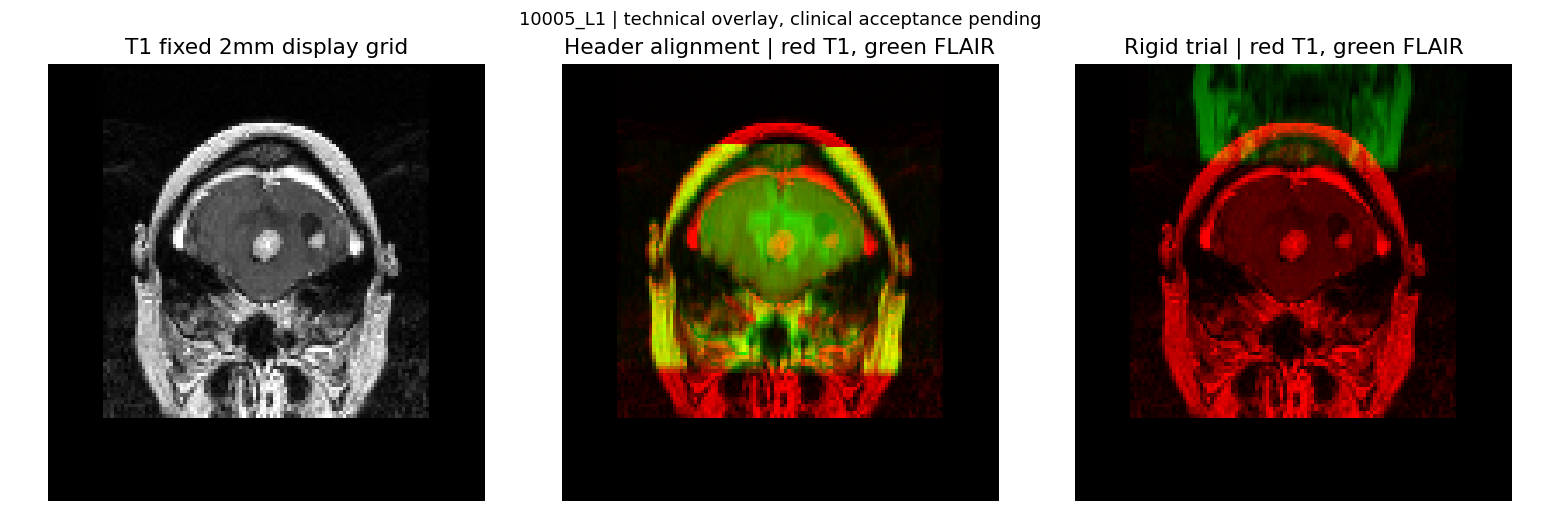

{
  "checked_date": "2026-10-29",
  "current_clinical_source_unchanged": true,
  "clinical_lesions": 160,
  "recorded_rn_times": 35,
  "unknown_rn": 125,
  "verified_non_events": 0,
  "verified_event_free_followup_records": 0,
  "baseline_mask_candidates": 54,
  "baseline_candidates_enabled_for_model": 0,
  "original_risk_prediction_model_ready": false,
  "prediction_model_fitted": false,
  "decision": "do_not_train_original_risk_model_with_current_verified_public_endpoints",
  "scope_limit": "Current verified source set; not proof that no additional public labels exist anywhere",
  "blockers": [
    "Blank RN does not establish an event-free outcome or censoring date",
    "Published diagnostic specificity cohorts do not provide verified pretreatment event-free follow-up for this cohort",
    "Public lesion-level reference-standard mapping remains incomplete"
  ],
  "next_action": "Prioritize public endpoint provenance or a fully labeled public cohort before expanding cohort-wide imag

In [4]:
gate=runpy.run_path(str(ROOT/'scripts/check_endpoint_gate.py'))['run'](refresh=False)
registry=json.loads((ROOT/'data/metadata/endpoint_gate_20261029/public_registry_recheck.json').read_text())
print('Registry tree:',registry['tree_sha'])
print('Observed example ids:',registry['example_registry_case_ids'])
assert gate['unknown_rn']==125 and gate['verified_non_events']==0
assert gate['verified_event_free_followup_records']==0
assert gate['original_risk_prediction_model_ready'] is False

## 当前决定

原定M0—M2风险模型不训练，不生成AUC。暂不扩大全队列自动配准，优先补齐公开终点依据或核查有完整公开标签的队列；影像技术试验不能解决结局不可识别。不会把空白RN、死亡、晚期MRI、模型概率或组织坏死掩膜改成阴性真值。

In [5]:
assert pilot['clinical_alignment_accepted']==0
assert pilot['source_images_or_masks_overwritten'] is False
assert pilot['derived_resampling_performed'] is True
assert pilot['prediction_model_fitted'] is False
print('Three registration trials complete. No candidate applied to analysis. Original risk-model gate remains closed.')

Three registration trials complete. No candidate applied to analysis. Original risk-model gate remains closed.
